# Batched homogeneous Teukolsky solutions with `hblteuk.jax`

Phase 2 of the GPU port: **Up and In homogeneous radial solutions for
thousands of modes in one call** — `vmap` over modes, `lax.scan` over the
sequential subdomain march, batched 32×32 LU solves per step.

Requires the `hblteuk-env` conda env (see `cluster/` for the GPU-cluster
setup). Design notes: `dev/GPU_PLAN.md` §2.1, `dev/PHASE2.md`; cross-checks
live in `examples/jax_teuk_validation.ipynb`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax

from hblteuk.geo import MiniGeo
from hblteuk.collocode import generate_subdomain_list
from hblteuk.teuk import sigma_r
from hblteuk.jax import (spheroidal_eigs_batched, solve_homogeneous_batch,
                         evaluate_multidomain)

C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]  # Okabe-Ito, fixed order
print("devices:", jax.devices())

devices: [CpuDevice(id=0)]


## 1. Mode table and shared subdomain structure

One orbit, all radiative $(\ell, m)$ modes to $\ell_{\max} = 25$. The whole
batch shares one fixed subdomain structure per family — the property the
grid generator's `optimize()` guarantees in production. Up marches from
$\sigma = 0$ (scri), In from $\sigma = 1$ (horizon).

In [2]:
orbit = MiniGeo(0.9, 10.0, 0.0, 1.0)
a = orbit.a
kappa = np.sqrt(1 - a**2)
smin = sigma_r(orbit.radial_roots[0], kappa)   # particle -> horizon side
smax = sigma_r(orbit.radial_roots[1], kappa)   # particle -> scri side

subs_up = generate_subdomain_list([0, smax], 150, "arcsinh7")
subs_in = generate_subdomain_list([1, smin], 150, "arcsinh7")

lmax = 25
modes = [(l, m) for l in range(2, lmax + 1) for m in range(-l, l + 1) if m != 0]
l_arr = np.array([c[0] for c in modes])
m_arr = np.array([c[1] for c in modes])
omega = np.array([orbit.mode_frequency(m, 0, 0) for m in m_arr])

# Phase 1 supplies the eigenvalues, batched
lam, _, _ = spheroidal_eigs_batched(-2, l_arr, m_arr, a * omega)
lam = np.asarray(lam)
print(f"B = {len(modes)} radiative modes, "
      f"{len(subs_up)-1} subdomains x 32 nodes per family")

B = 648 radiative modes, 150 subdomains x 32 nodes per family


## 2. Solve everything at once

In [3]:
res = solve_homogeneous_batch(-2, kappa, lam, m_arr * a, omega,
                              subs_up, subs_in, n=32)
res.coeffs_up.block_until_ready()
print("coeffs_up:", res.coeffs_up.shape, "| coeffs_in:", res.coeffs_in.shape)
print(f"max relative residuals: Up {float(res.errors_up.max()):.1e}, "
      f"In {float(res.errors_in.max()):.1e}")

coeffs_up: (648, 150, 32) | coeffs_in: (648, 150, 32)
max relative residuals: Up 2.9e-13, In 6.8e-11


## 3. Solution profiles

$|\psi(\sigma)|$ for a few modes, both families, evaluated with the batched
multi-domain evaluator. Vertical dotted lines mark the particle's radial
range $[\sigma_{\min}, \sigma_{\max}]$ where the two families are joined by
the source integration.

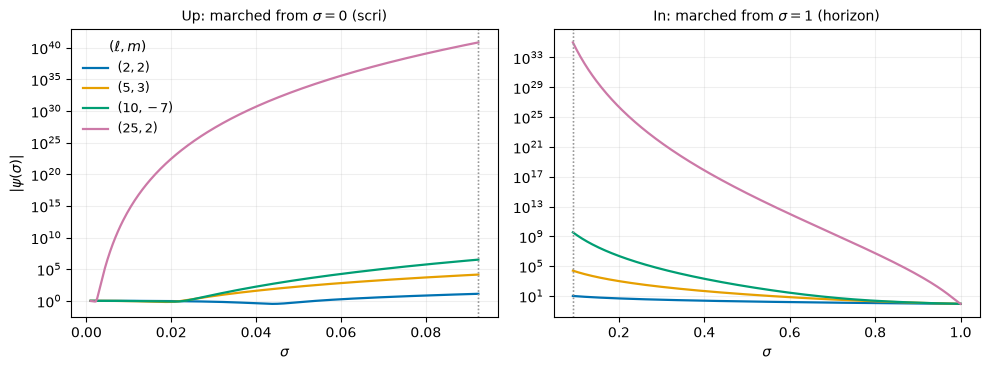

In [4]:
sig_up = np.linspace(1e-3, smax, 300)
sig_in = np.linspace(smin, 1 - 1e-6, 300)
show = [(2, 2), (5, 3), (10, -7), (25, 2)]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
for color, (l, m) in zip(C, show):
    b = modes.index((l, m))
    up = np.abs(np.asarray(evaluate_multidomain(res.coeffs_up, subs_up, sig_up))[b])
    inn = np.abs(np.asarray(evaluate_multidomain(res.coeffs_in, subs_in, sig_in))[b])
    axes[0].semilogy(sig_up, up, lw=1.6, color=color, label=rf"$({l},{m})$")
    axes[1].semilogy(sig_in, inn, lw=1.6, color=color)
for ax, ttl in zip(axes, [r"Up: marched from $\sigma=0$ (scri)",
                          r"In: marched from $\sigma=1$ (horizon)"]):
    for sp in (smin, smax):
        ax.axvline(sp, color="0.6", ls=":", lw=1)
    ax.set_xlabel(r"$\sigma$")
    ax.set_title(ttl, fontsize=10)
    ax.grid(alpha=0.2)
axes[0].set_ylabel(r"$|\psi(\sigma)|$")
axes[0].legend(frameon=False, fontsize=9, title=r"$(\ell, m)$")
plt.tight_layout()

## 4. Per-mode convergence flags

`errors` is the relative per-domain residual $\|M c\| / \|c\|$ — the
batched analogue of the CPU solver's error metric. On a generic (non-
optimized) subdomain structure the extreme high-$\ell$ In modes lose
accuracy — precisely the modes `optimize()` tunes the structure for. The
map makes the failure region visible at a glance.

modes with residual > 1e-10: 0 of 648


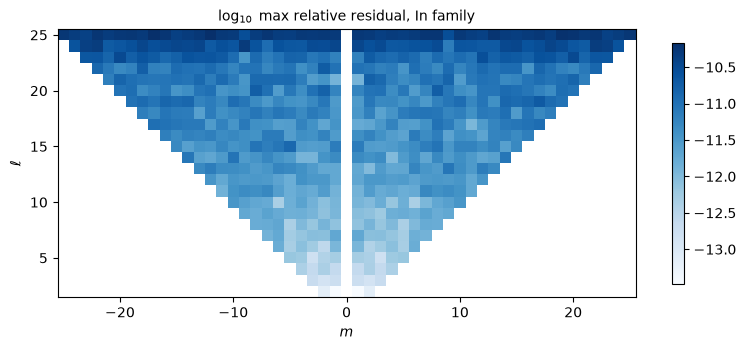

In [5]:
err = np.asarray(res.errors_in).max(axis=1)
grid = np.full((lmax - 1, 2 * lmax + 1), np.nan)
for b, (l, m) in enumerate(modes):
    grid[l - 2, m + lmax] = np.log10(err[b])

fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(grid, origin="lower", aspect="auto", cmap="Blues",
               extent=[-lmax - 0.5, lmax + 0.5, 1.5, lmax + 0.5])
ax.set_xlabel(r"$m$"); ax.set_ylabel(r"$\ell$")
ax.set_title(r"$\log_{10}$ max relative residual, In family", fontsize=10)
fig.colorbar(im, shrink=0.9)
plt.tight_layout()
print(f"modes with residual > 1e-10: {int(np.sum(err > 1e-10))} of {len(err)}")

## 5. Timing

In [6]:
t0 = time.perf_counter()
res2 = solve_homogeneous_batch(-2, kappa, lam, m_arr * a, omega,
                               subs_up, subs_in, n=32)
res2.coeffs_up.block_until_ready()
t_batch = time.perf_counter() - t0

# CPU reference: fixed-domain solver, timed on a subset and extrapolated
from hblteuk import collocode
from hblteuk.teuk import HyperboloidalTeukolskySolver
solver = collocode.CollocationODEFixedMultiDomainFixedStepSolver(n=32)
ts = HyperboloidalTeukolskySolver(
    domains=[[0, smax], [smin, 1]], solver=solver,
    subdomains={"Up": subs_up, "In": subs_in})
nsub = 20
t0 = time.perf_counter()
for b in range(nsub):
    ts(a, -2, int(l_arr[b]), int(m_arr[b]), omega[b], eigenvalue=lam[b])
t_cpu = (time.perf_counter() - t0) / nsub * len(modes)

plat = jax.devices()[0].platform.upper()
print(f"batched ({plat}, cached compile): {t_batch:6.2f} s for B = {len(modes)}")
print(f"CPU per-mode loop (extrapolated): {t_cpu:6.1f} s")
print(f"speedup: {t_cpu/t_batch:.0f}x")

batched (CPU, cached compile):   0.74 s for B = 648
CPU per-mode loop (extrapolated):   13.5 s
speedup: 18x


On CPU-JAX the win is bounded by the serial 150-step scan; on an A100
the batched LU steps are the target workload (`cluster/benchmark_gpu.py`
reproduces this table there). Next: Phase 3 — batched source integration.